In [82]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load and preprocess dataset
dataset_original = read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',', engine='python')
dataset_original['Time'] = pd.to_datetime(dataset_original['Time'])
dataset_original.set_index('Time', inplace=True)
dataset_original.sort_index(inplace=True)

# Fix random seed for reproducibility
tf.keras.utils.set_random_seed(42)  # sets seeds for base-python, numpy and tf
tf.config.experimental.enable_op_determinism()

# Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset_original[['Parkings', 'day_of_year', 'weekday', 'hour', 'is_holiday']])

# Create sequences
SEQ_LENGTH = 96

def create_sequence(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

def inverse_transform(scaler, data, dataset_shape):
    zeros = np.zeros((data.shape[0], dataset_shape[1] - 1))
    concatenated = np.concatenate((data, zeros), axis=1)
    return scaler.inverse_transform(concatenated)[:, 0]

def calculate_metrics(actual, predicted, dataset_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f'{dataset_name} MAE: {mae}, {dataset_name} RMSE: {rmse}')
    return mae, rmse


In [83]:
# Split data into train, validation, and test sets
train_size = int(len(dataset) * 0.70)
validation_size = int(len(dataset) * 0.15)
test_size = int(len(dataset) * 0.15)

train_df = dataset[0:train_size]
validation_df = dataset[train_size:train_size+validation_size]
test_df = dataset[train_size+validation_size:]

trainX, trainY = create_sequence(train_df, SEQ_LENGTH)
validationX, validationY = create_sequence(validation_df, SEQ_LENGTH)
testX, testY = create_sequence(test_df, SEQ_LENGTH)

# Create and compile the model
model = Sequential()
model.add(LSTM(16, return_sequences=True, input_shape=(SEQ_LENGTH, trainX.shape[2]), dropout=0.2, recurrent_dropout=0.1))
model.add(LSTM(16, dropout=0.2, recurrent_dropout=0.1))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(trainX, trainY, validation_data=(validationX, validationY), epochs=50, callbacks=[early_stopping])


Epoch 1/50


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


199/199 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0570 - val_loss: 0.0121
Epoch 2/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0281 - val_loss: 0.0081
Epoch 3/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0209 - val_loss: 0.0080
Epoch 4/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0169 - val_loss: 0.0053
Epoch 5/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0162 - val_loss: 0.0066
Epoch 6/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0149 - val_loss: 0.0074
Epoch 7/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0134 - val_loss: 0.0076
Epoch 8/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0129 - val_loss: 0.0051
Epoch 9/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0117 - val_loss: 0.0058
Epoch 10/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0112 - val_loss: 0.0065
Epoch 11/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0108 - val_loss: 0.0072
Epoch 12/50
199/199 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/ste

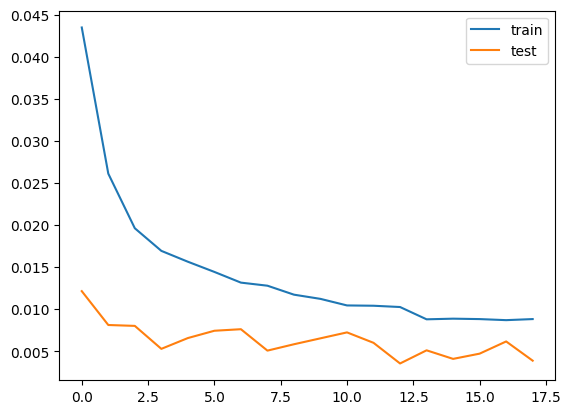

In [84]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [85]:
# Make predictions
train_predict = model.predict(trainX)
validation_predict = model.predict(validationX)
test_predict = model.predict(testX)

# Inverse transform predictions and actual values to original scale
train_predict = inverse_transform(scaler, train_predict, dataset.shape)
validation_predict = inverse_transform(scaler, validation_predict, dataset.shape)
test_predict = inverse_transform(scaler, test_predict, dataset.shape)
trainY_actual = inverse_transform(scaler, trainY.reshape(-1, 1), dataset.shape)
validationY_actual = inverse_transform(scaler, validationY.reshape(-1, 1), dataset.shape)
testY_actual = inverse_transform(scaler, testY.reshape(-1, 1), dataset.shape)

199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


Train MAE: 62.682646175708406, Train RMSE: 98.81480300382013
Validation MAE: 61.46830686583571, Validation RMSE: 83.5884230825515
Test MAE: 64.4632621738244, Test RMSE: 88.71631177857637


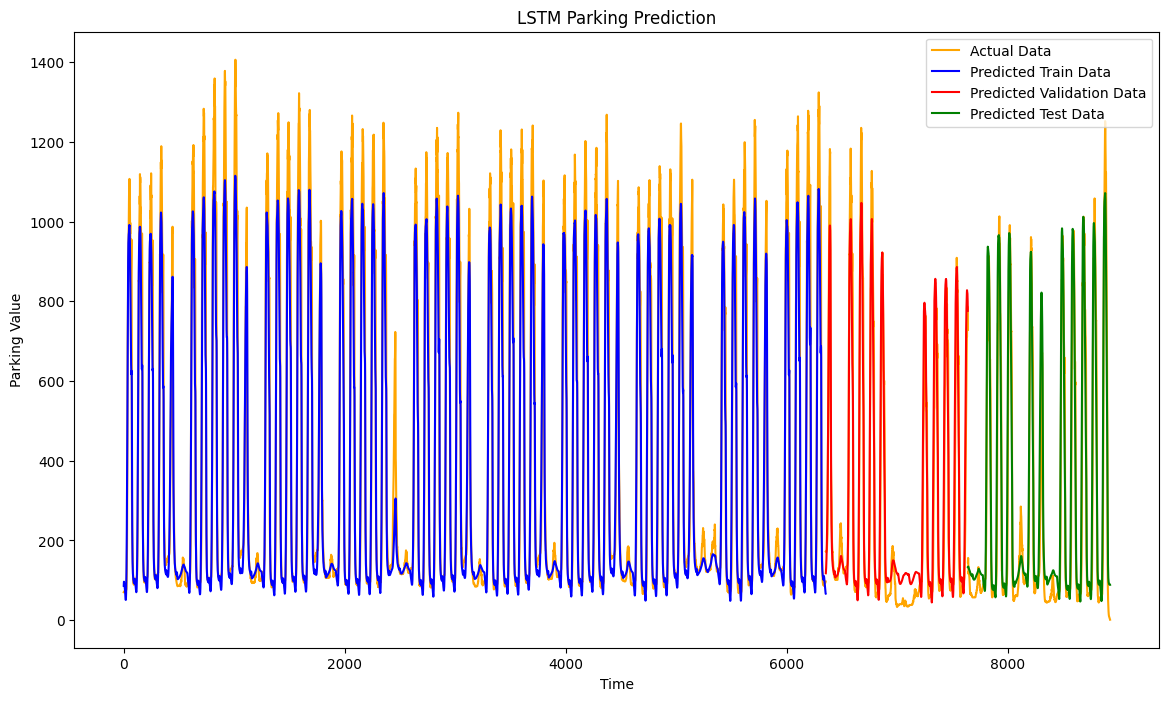

LSTM MAE: 64.4632621738244, RMSE: 88.71631177857637


In [86]:
# Calculate and print MAE and RMSE
train_mae, train_rmse = calculate_metrics(trainY_actual, train_predict, 'Train')
validation_mae, validation_rmse = calculate_metrics(validationY_actual, validation_predict, 'Validation')
test_mae, test_rmse = calculate_metrics(testY_actual, test_predict, 'Test')

# Plot the results
plt.figure(figsize=(14, 8))
plt.plot(trainY_actual, label='Actual Data', color='orange')
plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validationY_actual, color='orange')
plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(testY_actual)), testY_actual, color='orange')

plt.plot(train_predict, label='Predicted Train Data', color='b')
plt.plot(range(len(trainY_actual), len(trainY_actual) + len(validationY_actual)), validation_predict, label='Predicted Validation Data', color='r')
plt.plot(range(len(trainY_actual) + len(validationY_actual), len(trainY_actual) + len(validationY_actual) + len(test_predict)), test_predict, label='Predicted Test Data', color='g')

plt.xlabel('Time')
plt.ylabel('Parking Value')
plt.title('LSTM Parking Prediction')
plt.legend()
plt.show()

print(f'LSTM MAE: {test_mae}, RMSE: {test_rmse}')

77.1913079184694